# Ch.2 — From VAEs to DDPM

**Goal:** ground the ELBO machinery on a VAE, then build DDPM from scratch
twice (2D toy data → MNIST), reproducing the derivations in Ch. 2.1–2.2.

**Structure**
1. Part A — VAE on MNIST (ELBO, reparameterization trick)
2. Part B — DDPM theory recap (forward process, Lemma 2.2.2, ε/x₀ equivalence)
3. Part C — DDPM from scratch on 2D toy data (MLP, ancestral sampling)
4. Part D — DDPM on MNIST (small conv-U-Net)
5. Checkpoint — visual + quantitative sanity checks

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


## 2.1 Variational Autoencoder

A VAE assumes a latent-variable model $p(x, z) = p(x|z) \cdot p(z)$, with prior
$p(z) = N(0, I)$. Since the true posterior $p(z|x)$ is intractable, we
introduce an encoder $q_θ(z|x)$ and optimize the **Evidence Lower Bound**:

$$L_{ELBO}(x) = E_{q_θ(z|x)}[ log p_ϕ(x|z) ]  −  D_{KL}( q_θ(z|x) ‖ p(z) )$$

- First term: **reconstruction** (decoder likelihood).
- Second term: **regularizer** pulling the encoder's output toward the prior.

With $q_θ(z|x) = N(z; μ_θ(x), diag(σ_θ²(x)))$, the KL term is closed-form
(Gaussian-vs-standard-Gaussian KL), and sampling $z$ uses the
**reparameterization trick**: $z = μ + σ ⊙ ε, ε \sim N(0, I)$, which keeps the
sampling step differentiable w.r.t. θ.

This is the same "encoder maps data forward, decoder maps it back, bound
the log-likelihood" template that DDPM reuses in Part B — except DDPM fixes
the encoder and stacks many latent layers.

In [ ]:
# Data
transform = transforms.ToTensor()
train_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 19.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.44MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 13.2MB/s]


In [ ]:
# Model
class VAE(nn.Module):
    def __init__(self, latent_dim=16):
        super().__init__()
        self.enc = nn.Sequential(
            nn.Flatten(), nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU()
        )
        self.mu_head = nn.Linear(128, latent_dim)
        self.logvar_head = nn.Linear(128, latent_dim)
        self.dec = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(),
            nn.Linear(128, 256), nn.ReLU(),
            nn.Linear(256, 784), nn.Sigmoid()
        )

    def encode(self, x):
        h = self.enc(x)
        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(self, mu, logvar):
        std = (0.5 * logvar).exp()
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        return self.dec(z).view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

def vae_loss(x_hat, x, mu, logvar):
    recon = F.binary_cross_entropy(x_hat.flatten(1), x.flatten(1), reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (recon + kl) / x.size(0), recon / x.size(0), kl / x.size(0)

In [ ]:
vae = VAE().to(device)
opt = torch.optim.Adam(vae.parameters(), lr=1e-3)

for epoch in range(10):
    total = 0
    for x, _ in train_loader:
        x = x.to(device)
        x_hat, mu, logvar = vae(x)
        loss, recon, kl = vae_loss(x_hat, x, mu, logvar)
        opt.zero_grad(); loss.backward(); opt.step()
        total += loss.item() * x.size(0)
    print(f"epoch {epoch} | ELBO loss {total/len(train_ds):.2f}")

epoch 0 | ELBO loss 190.30
epoch 1 | ELBO loss 138.70
epoch 2 | ELBO loss 124.68
epoch 3 | ELBO loss 118.60
epoch 4 | ELBO loss 114.76
epoch 5 | ELBO loss 112.40
epoch 6 | ELBO loss 110.75
epoch 7 | ELBO loss 109.48
epoch 8 | ELBO loss 108.55
epoch 9 | ELBO loss 107.83


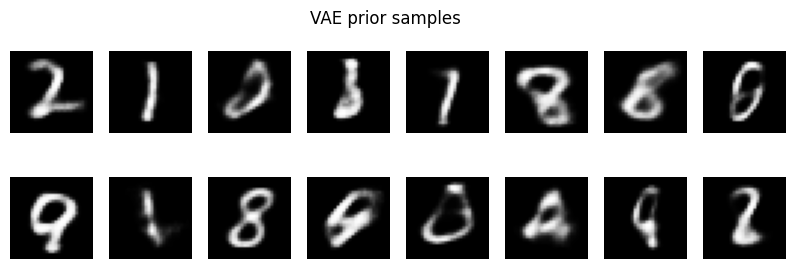

In [ ]:
vae.eval()
with torch.no_grad():
    z = torch.randn(16, 16).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i, 0], cmap="gray"); ax.axis("off")
plt.suptitle("VAE prior samples")
plt.show()

**Observation:** VAE samples are blurry — a single Gaussian decoder step has
to hallucinate all the detail at once. A **Hierarchical VAE** stacks latents
`z_1..z_L` to spread this over multiple stages, but training becomes unstable
(deep latents get weak gradient signal; shallow layers dominate reconstruction).

DDPM keeps the hierarchical, multi-step structure but makes one crucial
simplification: **fix the encoder** to a known, non-learned noising process,
and only learn the reverse (decoder) chain. That's Section 2.2.

## 2.2 DDPM

**Forward process (fixed encoder).** Gaussian transition kernel:

$$p(x_i \mid x_{i-1}) = \mathcal{N}\left(x_i ; \alpha_i x_{i-1}, \beta_i^2 I\right), \quad \text{with } \alpha_i = \sqrt{1-\beta_i^2}$$

Closing this recursively gives a direct jump from data to any noise level $i$:

$$x_i = \bar\alpha_i x_0 + \sqrt{1-\bar\alpha_i^2}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I), \qquad \bar\alpha_i = \prod_{k \le i} \alpha_k$$

This lets us sample any $x_i$ from $x_0$ in one shot — no need to simulate
the chain step by step during training.

**Reverse process (learnable decoder).** We want $p_\phi(x_{i-1} \mid x_i)$. The
*true* posterior conditioned on $x_0$ is tractable (Lemma 2.2.2):

$$p(x_{i-1} \mid x_i, x_0) = \mathcal{N}\left(x_{i-1}; \mu(x_i, x_0, i), \sigma^2(i) I\right)$$

so we parameterize $p_\phi(x_{i-1} \mid x_i) = \mathcal{N}\left(x_{i-1}; \mu_\phi(x_i,i), \sigma^2(i) I\right)$ and
match means via a KL loss — this is $L_{\text{DDPM}}$ in Eq. (2.2.8).

**$\epsilon$-prediction.** Substituting the closed-form $x_i$ back into $\mu$ gives a
noise-prediction parameterization: instead of predicting $\mu$ directly, a
network $\epsilon_\phi(x_i, i)$ predicts the noise that was added. The loss reduces to
plain MSE and is *equivalent up to a reweighting* to the original ELBO term:

$$L_{\text{simple}}(\phi) = \mathbb{E}_{i, x_0, \epsilon} \left[ \left\| \epsilon_\phi(x_i, i) - \epsilon \right\|^2 \right], \qquad x_i = \bar\alpha_i x_0 + \sqrt{1-\bar\alpha_i^2}\, \epsilon$$

This is what we implement below. ($x$-prediction and $v$-prediction are
algebraically equivalent reparameterizations — Week 6 revisits this.)

**Sampling (ancestral).** Starting from $x_L \sim \mathcal{N}(0,I)$, repeatedly:
1. Predict $\epsilon_\phi(x_i, i)$.
2. Estimate the mean of $p_\phi(x_{i-1} \mid x_i)$ from it.
3. Sample $x_{i-1}$ by adding calibrated noise $\sigma(i) z$, $z \sim \mathcal{N}(0,I)$ (except at $i=1$).


In [2]:
# Shared diffusion utilities
def make_schedule(T=1000, beta_start=1e-4, beta_end=0.02):
    """
    Builds the fixed forward-process schedule.
    betas:       beta_i, linearly increasing noise variance per step
    alphas:      alpha_i = 1 - beta_i   (per-step "signal retained" factor)
    alpha_bars:  cumulative product of alphas -> closed-form x_i from x_0
    """
    betas = torch.linspace(beta_start, beta_end, T)
    alphas = 1.0 - betas
    alpha_bars = torch.cumprod(alphas, dim=0)
    return betas, alphas, alpha_bars

T = 1000  # number of diffusion steps
betas, alphas, alpha_bars = [t.to(device) for t in make_schedule(T)]


def q_sample(x0, t, noise=None):
    """
    One-shot forward sampling: draws x_t ~ p(x_t | x_0) directly,
    `t` is a batch of integer timestep indices.
    """
    if noise is None:
        noise = torch.randn_like(x0)
    # Reshape alpha_bar[t] to broadcast against x0's shape
    # (e.g. (B,) -> (B,1) for 2D points, or (B,1,1,1) for images).
    ab = alpha_bars[t].view(-1, *([1] * (x0.dim() - 1)))
    return ab.sqrt() * x0 + (1 - ab).sqrt() * noise, noise

### 2.2.1 DDPM on 2D toy data
Before touching MNIST, we train and sample DDPM on a synthetic 2D
distribution. Therefore, we can see the whole distribution at once so we can debug easily.

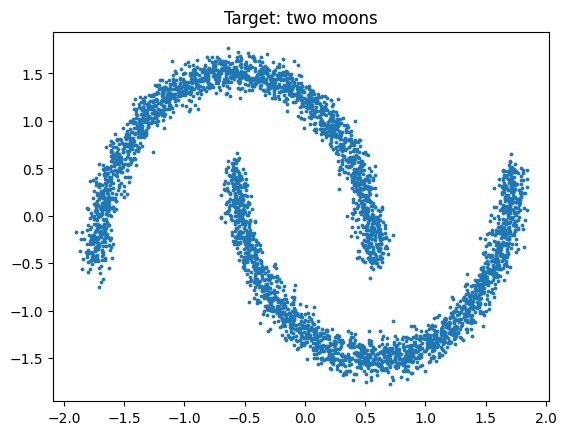

In [3]:
# Toy dataset
X, _ = make_moons(n_samples=4000, noise=0.05)
X = torch.tensor(X, dtype=torch.float32)
X = (X - X.mean(0)) / X.std(0)  # normalize to roughly unit variance

plt.scatter(X[:, 0], X[:, 1], s=3); plt.title("Target: two moons"); plt.show()

In [9]:
class SinusoidalEmbed(nn.Module):
    """
    Maps a scalar timestep t -> a fixed-size vector using sin/cos features
    at multiple frequencies (same idea as Transformer positional encodings).
    This gives the network a smooth, high-resolution signal for "which
    noise level am I looking at", instead of just feeding in the raw
    integer t.
    """
    def __init__(self, dim=32):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        # Geometrically spaced frequencies from 1 down to 1/10000
        freqs = torch.exp(-np.log(10000) * torch.arange(half, device=t.device) / half)
        args = t[:, None].float() * freqs[None]      # (batch, half)
        return torch.cat([torch.sin(args), torch.cos(args)], dim=-1)  # (batch, dim)


class ToyEpsNet(nn.Module):
    """
    Neural network `epsilon_phi(x_t, t)`: predicts the noise added to a 2D point x_t at
    timestep t. Take [x_t ; time_embedding] as input.
    """
    def __init__(self, dim=2, hidden=128, t_dim=32):
        super().__init__()
        self.temb = SinusoidalEmbed(t_dim)
        self.net = nn.Sequential(
            nn.Linear(dim + t_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, dim),   # output has same shape as input noise
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, self.temb(t)], dim=-1))

In [15]:
model = ToyEpsNet().to(device)
opt = torch.optim.Adam(model.parameters(), lr=2e-3)
X_dev = X.to(device)

for step in range(7000):
    # Sample a random mini-batch of clean data points x0
    idx = torch.randint(0, X_dev.size(0), (256,))
    x0 = X_dev[idx]

    # Sample a random timestep per example
    t = torch.randint(0, T, (x0.size(0),), device=device)

    # One-shot forward corruption: get x_t and the exact noise used to make it
    xt, noise = q_sample(x0, t)

    # Predict that noise and compare with simple MSE
    pred = model(xt, t)
    loss = F.mse_loss(pred, noise)

    opt.zero_grad(); loss.backward(); opt.step()
    if step % 500 == 0:
        print(f"step {step} | loss {loss.item():.4f}")

step 0 | loss 1.0141
step 500 | loss 0.2619
step 1000 | loss 0.3276
step 1500 | loss 0.3015
step 2000 | loss 0.3092
step 2500 | loss 0.2673
step 3000 | loss 0.2561
step 3500 | loss 0.2632
step 4000 | loss 0.2081
step 4500 | loss 0.2872
step 5000 | loss 0.2478
step 5500 | loss 0.2158
step 6000 | loss 0.3124
step 6500 | loss 0.2573


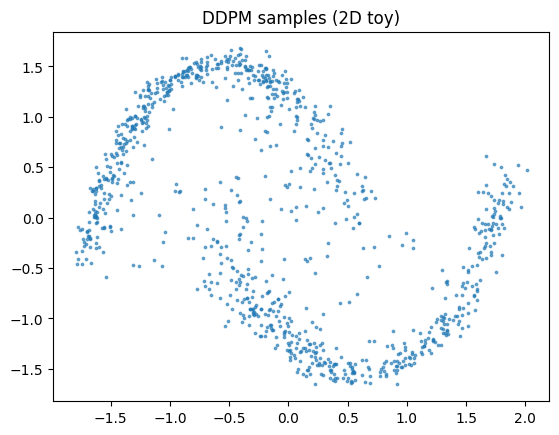

In [16]:
@torch.no_grad()
def ancestral_sample(model, shape, T, betas, alphas, alpha_bars, record_every=None):
    """
    Reverse diffusion sampling: start from pure Gaussian noise and
    iteratively denoise down to t=0.

    At each step i, the reverse mean is:
        mean = (1/sqrt(alpha_i)) * ( x_i - (1-alpha_i)/sqrt(1-alpha_bar_i) * eps_hat )
    which follows directly from solving Eq. (2.2.9) for x0, substituting into
    the closed-form mu(x_i, x0, i), and replacing the unknown noise with the
    network's prediction eps_hat.

    We add fresh noise scaled by sqrt(beta_i) at every step except the last
    (matching sigma(i) from Lemma 2.2.2, using the beta_i choice for sigma^2).
    """
    x = torch.randn(shape, device=device)   # x_L ~ N(0, I)
    traj = [x.cpu().clone()] if record_every else None

    for i in reversed(range(T)):
        t = torch.full((shape[0],), i, device=device, dtype=torch.long)
        eps_hat = model(x, t)

        alpha_i, ab_i = alphas[i], alpha_bars[i]
        mean = (1 / alpha_i.sqrt()) * (x - (1 - alpha_i) / (1 - ab_i).sqrt() * eps_hat)

        if i > 0:
            sigma = betas[i].sqrt()
            x = mean + sigma * torch.randn_like(x)   # stochastic step
        else:
            x = mean                                  # final step: no noise added

        if record_every and i % record_every == 0:
            traj.append(x.cpu().clone())

    return x.cpu(), traj

samples, traj = ancestral_sample(model, (1000, 2), T, betas, alphas, alpha_bars, record_every=200)

plt.scatter(samples[:, 0], samples[:, 1], s=3, alpha=0.6)
plt.title("DDPM samples (2D toy)"); plt.show()

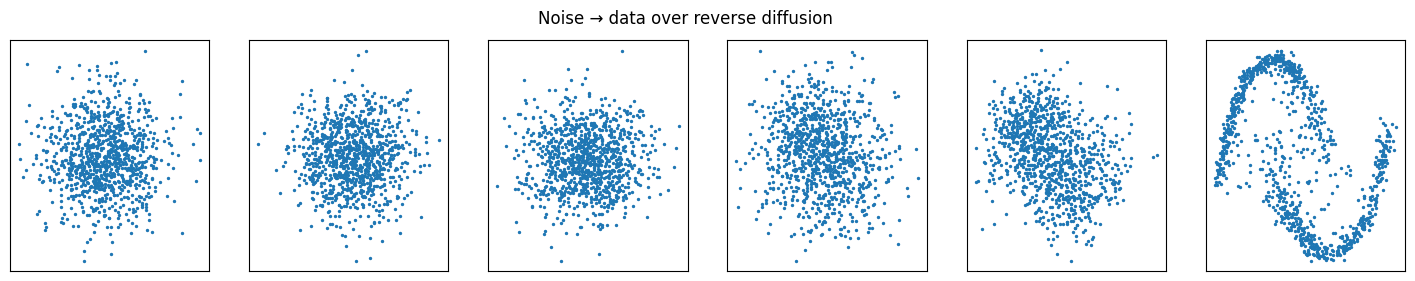

In [17]:
# `traj` holds snapshots of the particle cloud at evenly spaced timesteps,
# from pure noise (leftmost) down to the final samples (rightmost).
# Watching the shape emerge is the fastest way to sanity-check the sampler.
fig, axes = plt.subplots(1, len(traj), figsize=(3 * len(traj), 3))
for ax, snap in zip(axes, traj):
    ax.scatter(snap[:, 0], snap[:, 1], s=2)
    ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Noise → data over reverse diffusion")
plt.show()

### 2.2.2 DDPM on MNIST

2D data only needs coordinates + time. Images need spatial inductive bias.
We use a compact conv net with time-conditioned residual blocks instead of a
full U-Net — same mechanism ($\varepsilon$-prediction, identical training
loop), less boilerplate. Swap in a real U-Net later if you want sharper samples.

In [18]:
# Rescale data to [-1, 1]
transform_img = transforms.Compose([
    transforms.ToTensor(),
    transforms.Lambda(lambda x: x * 2 - 1),
])
mnist_ds = datasets.MNIST(root="./data", train=True, download=True, transform=transform_img)
mnist_loader = DataLoader(mnist_ds, batch_size=128, shuffle=True)

100%|██████████| 9.91M/9.91M [00:00<00:00, 17.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 480kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.38MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.76MB/s]


In [23]:
class ResBlock(nn.Module):
    """
    Time-conditioned residual block: two convs with
    GroupNorm + SiLU, and the timestep embedding injected as a per-channel
    bias partway through
    """
    def __init__(self, in_ch, out_ch, t_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        # If channel counts differ, project the input so the residual add
        # still works; otherwise just pass x through unchanged.
        self.skip = nn.Conv2d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()

    def forward(self, x, temb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.t_proj(temb)[:, :, None, None]
        h = self.conv2(F.silu(self.norm2(h)))
        return h + self.skip(x)


class SelfAttention(nn.Module):
    """
    Single-head spatial self-attention over a feature map.
    Flattens H*W into a sequence, does standard scaled dot-product
    attention, reshapes back.
    """
    def __init__(self, ch):
        super().__init__()
        self.norm = nn.GroupNorm(8, ch)
        self.qkv = nn.Conv2d(ch, ch * 3, 1)
        self.proj = nn.Conv2d(ch, ch, 1)

    def forward(self, x):
        B, C, H, W = x.shape
        h = self.norm(x)
        q, k, v = self.qkv(h).chunk(3, dim=1)          # each (B, C, H, W)
        q = q.reshape(B, C, H * W).permute(0, 2, 1)     # (B, HW, C)
        k = k.reshape(B, C, H * W)                      # (B, C, HW)
        v = v.reshape(B, C, H * W).permute(0, 2, 1)     # (B, HW, C)

        attn = torch.softmax(q @ k / (C ** 0.5), dim=-1)  # (B, HW, HW)
        out = (attn @ v).permute(0, 2, 1).reshape(B, C, H, W)
        return x + self.proj(out)   # residual


class Downsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.op = nn.Conv2d(ch, ch, 3, stride=2, padding=1)  # learned downsampling

    def forward(self, x):
        return self.op(x)


class Upsample(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.up = nn.Upsample(scale_factor=2, mode="nearest")
        self.conv = nn.Conv2d(ch, ch, 3, padding=1)  # smooth after upsampling

    def forward(self, x):
        return self.conv(self.up(x))


class UNet(nn.Module):
    """
    Real multi-resolution U-Net for epsilon_phi(x_t, t) on MNIST (28x28x1).

    Resolution path:  28x28 -> 14x14 -> 7x7 (bottleneck, w/ attention) -> 14x14 -> 28x28
    Channel widths:   base_ch -> base_ch*2 -> base_ch*4

    Every downsampling stage's output is stashed in `skips` and concatenated
    back in at the matching upsampling stage -- this is the defining feature
    of a U-Net versus a plain encoder-decoder.
    """
    def __init__(self, base_ch=64, t_dim=256):
        super().__init__()
        self.temb = nn.Sequential(
            SinusoidalEmbed(t_dim), nn.Linear(t_dim, t_dim), nn.SiLU(),
            nn.Linear(t_dim, t_dim),
        )

        ch1, ch2, ch3 = base_ch, base_ch * 2, base_ch * 4

        # --- Encoder (downsampling path) ---
        self.in_conv = nn.Conv2d(1, ch1, 3, padding=1)          # 28x28, ch1
        self.down1_res = ResBlock(ch1, ch1, t_dim)               # 28x28, ch1
        self.down1_ds = Downsample(ch1)                          # -> 14x14, ch1

        self.down2_res = ResBlock(ch1, ch2, t_dim)                # 14x14, ch2
        self.down2_ds = Downsample(ch2)                           # -> 7x7, ch2

        self.down3_res = ResBlock(ch2, ch3, t_dim)                # 7x7, ch3

        # --- Bottleneck (lowest resolution, with attention) ---
        self.mid_res1 = ResBlock(ch3, ch3, t_dim)
        self.mid_attn = SelfAttention(ch3)
        self.mid_res2 = ResBlock(ch3, ch3, t_dim)

        # --- Decoder (upsampling path) ---
        # Input channels double where we concatenate the matching skip connection.
        self.up3_res = ResBlock(ch3 + ch3, ch2, t_dim)            # 7x7 -> merge skip from down3
        self.up3_us = Upsample(ch2)                               # -> 14x14

        self.up2_res = ResBlock(ch2 + ch2, ch1, t_dim)            # merge skip from down2
        self.up2_us = Upsample(ch1)                               # -> 28x28

        self.up1_res = ResBlock(ch1 + ch1, ch1, t_dim)            # merge skip from down1

        self.out_norm = nn.GroupNorm(8, ch1)
        self.out_conv = nn.Conv2d(ch1, 1, 3, padding=1)           # predicted noise, 1 channel

    def forward(self, x, t):
        temb = self.temb(t)

        # Encoder, stashing outputs for skip connections
        h = self.in_conv(x)
        h1 = self.down1_res(h, temb)          # skip #1  (28x28, ch1)
        h = self.down1_ds(h1)

        h2 = self.down2_res(h, temb)          # skip #2  (14x14, ch2)
        h = self.down2_ds(h2)

        h3 = self.down3_res(h, temb)          # skip #3  (7x7,  ch3)

        # Bottleneck
        h = self.mid_res1(h3, temb)
        h = self.mid_attn(h)
        h = self.mid_res2(h, temb)

        # Decoder, concatenating matching skip at each level
        h = torch.cat([h, h3], dim=1)
        h = self.up3_res(h, temb)
        h = self.up3_us(h)

        h = torch.cat([h, h2], dim=1)
        h = self.up2_res(h, temb)
        h = self.up2_us(h)

        h = torch.cat([h, h1], dim=1)
        h = self.up1_res(h, temb)

        h = F.silu(self.out_norm(h))
        return self.out_conv(h)

In [24]:
# Same training loop as before -- only the model class changes.
img_model = UNet(base_ch=64).to(device)
opt = torch.optim.Adam(img_model.parameters(), lr=2e-4)

n_epochs = 5
for epoch in range(n_epochs):
    for x0, _ in mnist_loader:
        x0 = x0.to(device)
        t = torch.randint(0, T, (x0.size(0),), device=device)
        xt, noise = q_sample(x0, t)
        pred = img_model(xt, t)
        loss = F.mse_loss(pred, noise)
        opt.zero_grad(); loss.backward(); opt.step()
    print(f"epoch {epoch} | loss {loss.item():.4f}")

epoch 0 | loss 0.0404
epoch 1 | loss 0.0245
epoch 2 | loss 0.0239
epoch 3 | loss 0.0241
epoch 4 | loss 0.0287


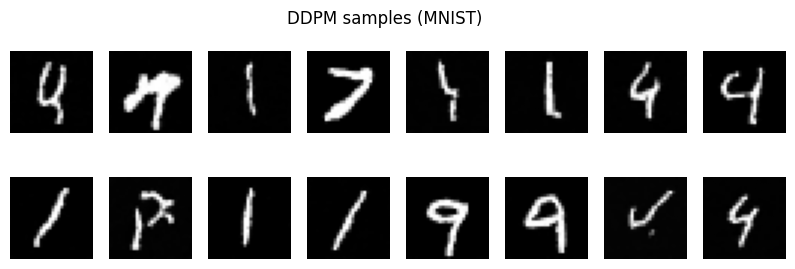

In [25]:
@torch.no_grad()
def ancestral_sample_img(model, n, T, betas, alphas, alpha_bars):
    """Same ancestral sampling loop as Part C, just operating on image tensors."""
    x = torch.randn(n, 1, 28, 28, device=device)
    for i in reversed(range(T)):
        t = torch.full((n,), i, device=device, dtype=torch.long)
        eps_hat = model(x, t)
        alpha_i, ab_i = alphas[i], alpha_bars[i]
        mean = (1 / alpha_i.sqrt()) * (x - (1 - alpha_i) / (1 - ab_i).sqrt() * eps_hat)
        x = mean if i == 0 else mean + betas[i].sqrt() * torch.randn_like(x)
    return x.cpu()

imgs = ancestral_sample_img(img_model, 16, T, betas, alphas, alpha_bars)
imgs = (imgs.clamp(-1, 1) + 1) / 2  # undo the [-1,1] rescale for display

fig, axes = plt.subplots(2, 8, figsize=(10, 3))
for i, ax in enumerate(axes.flat):
    ax.imshow(imgs[i, 0], cmap="gray"); ax.axis("off")
plt.suptitle("DDPM samples (MNIST)")
plt.show()